In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
from matplotlib import pyplot as plt

In [2]:
sns.set_theme(style='whitegrid')

In [4]:
df = pd.read_csv('C:/Users/HP/Documents/learn-data-journy/insurance_lab/data/raw/insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [4]:
print(f'shape : {df.shape} \n ---------')
print(f'data types :\n{df.dtypes}\n ---------')

shape : (1338, 7) 
 ---------
data types :
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object
 ---------


In [5]:
print(f'NAN value : \n{df.isnull().sum()}\n ---------')

NAN value : 
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
 ---------


In [6]:
print(f'duplacated : \n{df.duplicated().sum()}')

duplacated : 
1


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.describe(include='object')

C:\Users\HP\AppData\Local\Temp\ipykernel_6344\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,sex,smoker,region
count,1338,1338,1338
unique,2,2,4
top,male,no,southeast
freq,676,1064,364


In [11]:
# mean & median 
mean_charge = df['charges'].mean()
median_charge = df['charges'].median()
print(f'mean : {mean_charge}')
print(f'median : {median_charge}\n ---------')

# Q1 & Q3 & IQR
Q1 = df['charges'].quantile(0.25)
Q3 = df['charges'].quantile(0.75)
IQR = Q3 - Q1
print(f'Q1 = {Q1}\nQ3 = {Q3}\nIQR = {IQR}\n ----------')

# lower & Upper 
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
print(f'lower = {lower}\nupper = {upper}\n ---------')

# outliers 
outliers = df[(df['charges'] > upper) | (df['charges'] < lower)]
print(f'outliers = {len(outliers)}')

mean : 13270.422265141257
median : 9382.033
 ---------
Q1 = 4740.28715
Q3 = 16639.912515
IQR = 11899.625365
 ----------
lower = -13109.1508975
upper = 34489.350562499996
 ---------
outliers = 139


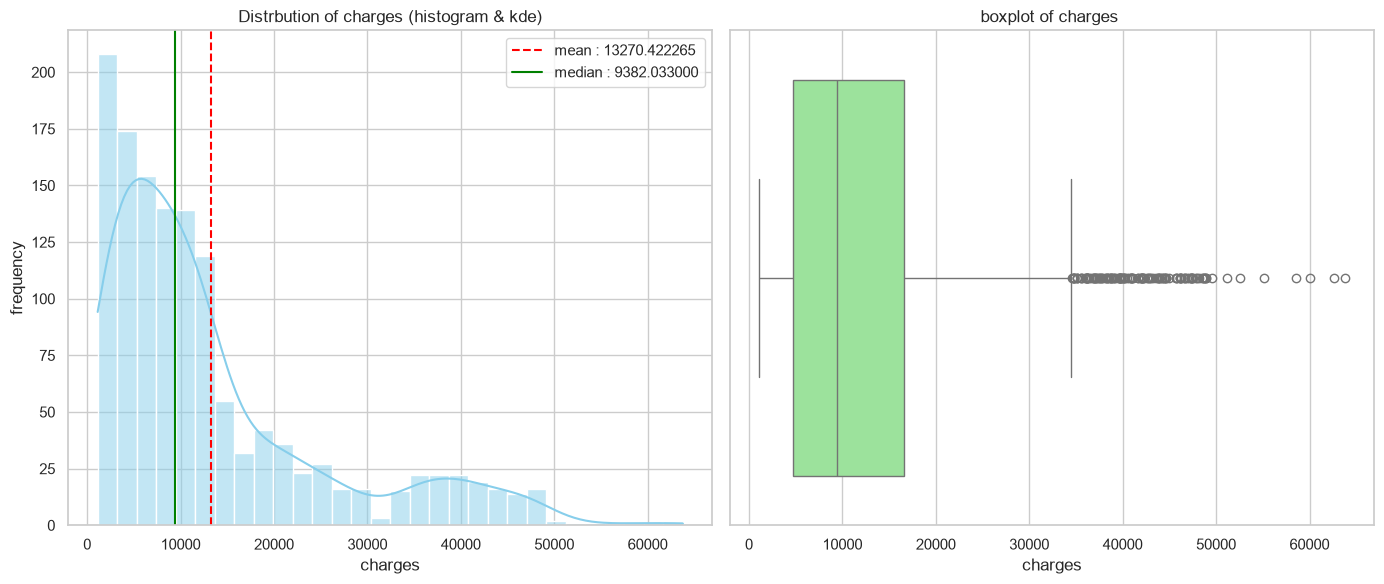

In [31]:
plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
sns.histplot(data=df , x=df['charges'],kde=True , bins=30 , color='skyblue')

plt.axvline(mean_charge ,color='red',linestyle='--' ,label=f'mean : {mean_charge:0f}')
plt.axvline(median_charge,color='green',linestyle='-' ,label=f'median : {median_charge:0f}')
plt.title('Distrbution of charges (histogram & kde)')
plt.xlabel('charges')
plt.ylabel('frequency')
plt.legend()

plt.subplot(1,2,2)
sns.boxplot(data=df , x=df['charges'] , color='lightgreen')
plt.title('boxplot of charges ')
plt.xlabel('charges')

plt.tight_layout()
plt.savefig('../reports/figures/1_distribution(charges)_and_boxplot(smoker).png',dpi=300 ,bbox_inches='tight')
plt.show()
plt.close()

C:\Users\HP\AppData\Local\Temp\ipykernel_6344\2134307837.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df , x= 'smoker',y='charges' , palette='Set2')


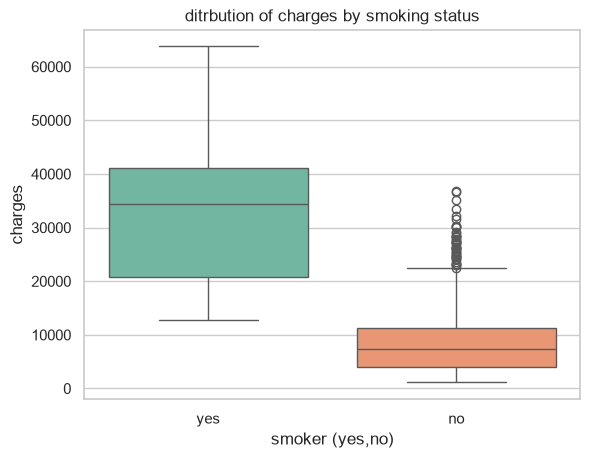

In [32]:
plt.Figure(figsize=(8,6))
sns.boxplot(data=df , x= 'smoker',y='charges' , palette='Set2')
plt.title('ditrbution of charges by smoking status')
plt.xlabel('smoker (yes,no)')
plt.ylabel("charges")
plt.savefig('../reports/figures/2_disribution_of_charges_by_smoking.png',dpi=300 ,bbox_inches='tight')
plt.show()
plt.close()

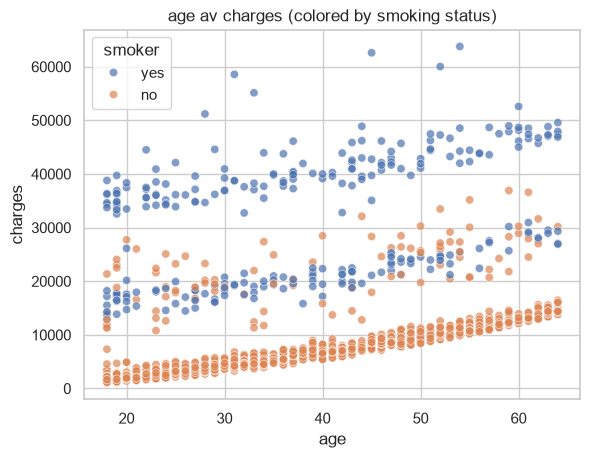

In [33]:
plt.Figure(figsize=(10,6))
sns.scatterplot(data=df , x='age' , y='charges' , hue='smoker' , alpha=0.7)
plt.title('age av charges (colored by smoking status)')
plt.xlabel('age')
plt.ylabel('charges')
plt.savefig('../reports/figures/3_correlation_age_vs_charges.png',dpi=300,bbox_inches='tight')
plt.show()

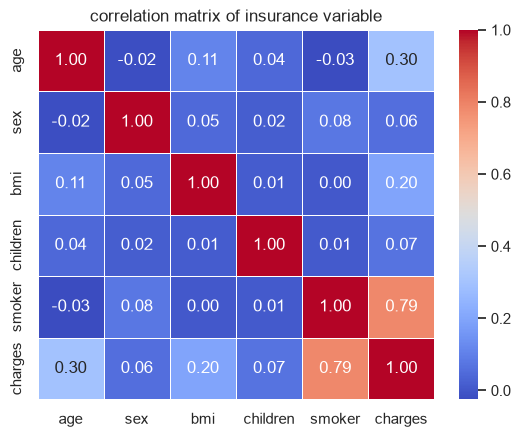

In [ ]:
df_encoded = df.copy()

df_encoded['smoker'] = df_encoded['smoker'].map({'yes':1 , 'no':0})
df_encoded['sex'] = df_encoded['sex'].map({'male':1 ,'female':0})
corr_matrix = df_encoded.drop('region',axis=1).corr()

plt.Figure(figsize=(10,8))
sns.heatmap(corr_matrix ,annot=True ,cmap='coolwarm' ,fmt='.2f' , linewidths=0.5)
plt.title('correlation matrix of insurance variable')
plt.savefig('../reports/figures/4_correlation_matrix_of_insurance_variable.png',dpi=300,bbox_inches='tight')
plt.show()

# تقرير استكشاف البيانات (EDA Report) - تكاليف التأمين الصحي

**تاريخ التقرير:** 2023-10-27
**معد التقرير:** [اسمك هنا]
**حالة البيانات:** خام (Raw)

---

## 1. نظرة عامة على البيانات
*   **حجم البيانات:** 1338 صفاً (مؤمَّن عليه)، و 7 أعمدة.
*   **جودة البيانات:** لا توجد قيم مفقودة (Missing Values) في أي عمود. تم اكتشاف **صف مكرر واحد**.
*   **أنواع البيانات:** جميع الأنواع منطقية.

## 2. تحليل المتغير المستهدف (charges)

يوضح الرسم البياني أدناه أن التوزيع **ملتوٍ بشدة لليمين (Right-Skewed)**. لاحظ كيف أن المتوسط (الخط الأحمر) انسحب بعيداً نحو اليمين بسبب القيم المتطرفة، بينما الوسيط (الخط الأخضر) يعبر عن الشخص النموذجي.

![توزيع التكاليف]('../reports/figures/1_distribution(charges)_and_boxplot(smoker).png')

*   **القرار:** الاعتماد على **الوسيط (9382)** كأفضل مقياس للتكلفة النموذجية بدلاً من المتوسط (13270).
*   **القيم الشاذة (Outliers):** باستخدام قاعدة (1.5 × IQR)، تم اكتشاف **139 حالة** تتجاوز الحد الأعلى (34,489). هذه القيم حقيقية وتمثل حالات مرضية كبرى.

## 3. استكشاف العلاقات (Bivariate Analysis)

### أ. تأثير التدخين (Smoker)
التدخين هو **المتغير الأقوى** على الإطلاق (معامل ارتباط 0.79). يظهر الرسم أدناه أن وسيط تكاليف المدخنين أعلى بكثير، وأنهم يبدأون بتكاليف مرتفعة حتى في الأعمار الصغيرة.

![تأثير التدخين]('../reports/figures/2_disribution_of_charges_by_smoking.png')

### ب. تأثير العمر والتدخين معاً (Age vs Charges)
عند رسم العمر مقابل التكاليف وتلوين النقاط حسب التدخين، تظهر البيانات في 3 تجمعات منفصلة. هذا يثبت أن العلاقة بين العمر والتكاليف ليست خطاً بسيطاً، بل تتأثر بشدة بمتغير التدخين المربك (Confounder).

![العمر والتكاليف]('../reports/figures/3_correlation_age_vs_charges.png')

### ج. العلاقة بين جميع الصفوف
![العلاقة_بين_جميع_الاعمدة]('../reports/figures/4_correlation_matrix_of_insurance_variable.png') 

## 4. التوصيات للمرحلة التالية (Data Preparation)
1.  حذف الصف المكرر.
2.  تحويل المتغيرات الفئوية (مثل `smoker` و `sex`) إلى صيغة رقمية (0/1).
3.  معالجة متغير `region` بطريقة لا تفترض ترتيباً (One-Hot Encoding).